## This LTM has both read and write capability

In [ ]:
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_groq import ChatGroq
from langchain_core.runnables import RunnableConfig
from langchain_core.messages import SystemMessage
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore
from langgraph.graph import StateGraph, MessagesState, START, END
import uuid
import os
from typing import List
from pydantic import BaseModel, Field
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
store = InMemoryStore()

In [3]:
# ----------------------------
# 2) System prompt
# ----------------------------
SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible.

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content}
"""

In [ ]:
# 2. LLM that decides what to remember (structred output)
# extractor_llm = ChatOllama(model="nemotron-3-nano:30b-cloud",format="json")
memory_llm = ChatGroq(model="openai/gpt-oss-120b")

In [5]:
class MemoryItem(BaseModel):
    text: str = Field(description="Atomic user memory as a short sentence")
    is_new: bool = Field(description="True if this memory is New and should be stored. False if duplicate/already known.")

In [6]:
class MemoryDecision(BaseModel):
    should_write: bool
    memories: List[MemoryItem] = Field(default_factory=list)

In [7]:
memory_extractor = memory_llm.with_structured_output(MemoryDecision)

In [8]:
MEMORY_PROMPT = """You are responsible for updating and maintaining accurate user memory.

CURRENT USER DETAILS (existing memories):
{user_details_content}

TASK:
- Review the user's latest message.
- Extract user-specific info worth storing long-term (identity, stable preferences, ongoing projects/goals).
- For each extracted item, set is_new=true ONLY if it adds NEW information compared to CURRENT USER DETAILS.
- If it is basically the same meaning as something already present, set is_new=false.
- Keep each memory as a short atomic sentence.
- No speculation; only facts stated by the user.
- If there is nothing memory-worthy, return should_write=false and an empty list.
"""

In [9]:
# ----------------------------
# 4) Node 1: remember
# ----------------------------
def remember_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    # existing memory
    items = store.search(ns)
    existing = "\n".join(it.value["data"] for it in items) if items else "(empty)"

    # last user message
    last_msg = state["messages"][-1].content

    decision: MemoryDecision = memory_extractor.invoke(
        [
            SystemMessage(content=MEMORY_PROMPT.format(user_details_content=existing)),
            {"role": "user", "content": last_msg},
        ]
    )

    if decision.should_write:
        for mem in decision.memories:
            if mem.is_new:
                store.put(ns, str(uuid.uuid4()), {"data": mem.text})

    return {}  # no message change

In [10]:
# ----------------------------
# 5) Node 2: chat
# ----------------------------
chat_llm = ChatOllama(model="beam:cloud")

In [11]:
def chat_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    items = store.search(ns)
    user_details = "\n".join(it.value["data"] for it in items) if items else ""

    system_msg = SystemMessage(
        content=SYSTEM_PROMPT_TEMPLATE.format(
            user_details_content=user_details or "(empty)"
        )
    )

    response = chat_llm.invoke([system_msg] + state["messages"])
    return {"messages": [response]}

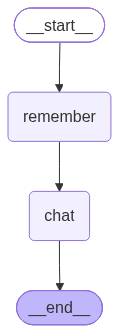

In [ ]:
# ----------------------------
# 6) Graph
# ----------------------------
builder = StateGraph(MessagesState)
builder.add_node("remember", remember_node)
builder.add_node("chat", chat_node)

builder.add_edge(START, "remember")
builder.add_edge("remember", "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [ ]:
# ----------------------------
# 7) Demo
# ----------------------------
config = {"configurable": {"user_id": "u1"}}

In [ ]:
result = graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is Nitish"}]}, config)
result['messages'][-1].content

"Hi Nitish! Great to meet you. 😊\n\nI'm here to help with whatever you need—whether it's coding, learning something new, brainstorming ideas, or just chatting. What are you working on today?\n\nHere are a few things we could dive into:\n\n1. Got a coding bug or project you'd like help with?\n2. Want to learn or explore a new topic?\n3. Need help drafting something—like an email, document, or plan?\n\nJust let me know what's on your mind and we'll get started!"

In [15]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

The user’s name is Nitish.


In [16]:
result = graph.invoke({"messages": [{"role": "user", "content": "I teach AI on YouTube"}]}, config)
print(result['messages'][-1].content)

Great to meet you, Nitish! 🎯

I love that you're teaching AI on YouTube — that's a fantastic way to help others navigate such an exciting and fast-moving field. Who's your target audience — beginners, intermediate learners, or advanced practitioners?

I'll tailor future suggestions, examples, and explanations to keep things friendly, instructional, and YouTube-ready so they're easy for you to repurpose into lessons, scripts, or shorts.

Is there a specific AI topic, tool, or project you'd like help with today — for instance:
- Drafting a lesson script or outline
- Breaking down a complex concept for learners
- Building a demo project for a video
- Optimizing thumbnails/titles or hooks

Also, how can I best help on the teaching front — concise explanations, code-along demos, analogy-based walkthroughs, or structured curricula?


In [17]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

The user’s name is Nitish.
The user teaches AI on YouTube.


In [18]:
result = graph.invoke({"messages": [{"role": "user", "content": "Explain GenAI simply"}]}, config)
print(result['messages'][-1].content)

Sure, Nitish — here’s GenAI in plain terms:

**Generative AI** is AI that doesn’t just analyze data—it *creates* new content (text, images, music, code, video) by learning patterns from huge amounts of existing examples.

**Think of it like a very fast, very well-read student:**
- **Training:** It studies billions of pages, images, or sounds.
- **Pattern learning:** It learns “what usually comes next” and “what things look like.”
- **Generation:** You give it a prompt (“write a lesson intro,” “draw a robot”), and it predicts a plausible, new output.

**Key pieces (simple):**
- **Model** = the “brain” (e.g., LLM for text, diffusion model for images).
- **Prompt** = your instruction/question.
- **Tokens** = small chunks of text it predicts one by one.
- **Hallucination** = when it sounds confident but is wrong—so always verify facts.

For your YouTube AI teaching, a good hook: “GenAI is autocomplete on steroids—trained so well it can write whole scripts, not just finish sentences.”

**3 

In [19]:
for it in store.search(("user", "u1", "details")):
    print(it.value["data"])

The user’s name is Nitish.
The user teaches AI on YouTube.
